# **Land Use Classification from Satellite Images with Deep Learning**

## **DSA4050 Term Paper**

### **Name:** Claire Mwarari

### **Student ID:** 669470

In this project I use deep learning to classify satellite images into 10 land use classes (forest, farmland, residential areas, highways and so on). This kind of classification is used in environmental monitoring, urban planning and agriculture. I train and compare several models in PyTorch, study overfitting and optimizers, check the final model with cross validation, and finish with an interactive dashboard.

## 1. Getting the dataset

I used the **EuroSAT** dataset. It contains 27,000 RGB satellite images (64 x 64 pixels) taken by the Sentinel-2 satellite, split into 10 land use classes. The dataset is hosted on Kaggle. The original source is the EuroSAT project by Helber et al. (2019).

In [1]:
import os, zipfile

# main source: Kaggle. fallback: the official EuroSAT server
KAGGLE_URL = 'https://www.kaggle.com/api/v1/datasets/download/waseemalastal/eurosat-rgb-dataset'
OFFICIAL_URL = 'http://madm.dfki.de/files/sentinel/EuroSAT.zip'

if not os.path.exists('EuroSAT_data'):
    if not os.path.exists('eurosat.zip') or os.path.getsize('eurosat.zip') < 80_000_000:
        !wget -q -O eurosat.zip "$KAGGLE_URL" || true
    if not os.path.exists('eurosat.zip') or os.path.getsize('eurosat.zip') < 80_000_000:
        print('kaggle download failed, trying the official server')
        !wget -q -O eurosat.zip "$OFFICIAL_URL" || true
    with zipfile.ZipFile('eurosat.zip') as z:
        z.extractall('EuroSAT_data')
    print('dataset downloaded and extracted')
else:
    print('dataset folder already exists')

dataset downloaded and extracted


In [2]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('using device:', device)

using device: cuda


In [3]:
# load all images into numpy arrays, the class name is the parent folder name
image_paths = []
for root, dirs, files in os.walk('EuroSAT_data'):
    for f in sorted(files):
        if f.lower().endswith('.jpg'):
            image_paths.append(os.path.join(root, f))
image_paths.sort()

classes = sorted({os.path.basename(os.path.dirname(p)) for p in image_paths})
cls2idx = {c: i for i, c in enumerate(classes)}

X = np.empty((len(image_paths), 64, 64, 3), dtype=np.uint8)
y = np.empty(len(image_paths), dtype=np.int64)
for i, p in enumerate(image_paths):
    X[i] = np.asarray(Image.open(p).convert('RGB'), dtype=np.uint8)
    y[i] = cls2idx[os.path.basename(os.path.dirname(p))]

print('images:', X.shape)
print('classes:', classes)
print('images per class:', np.bincount(y))

images: (27000, 64, 64, 3)
classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
images per class: [3000 3000 3000 2500 2500 2000 2500 3000 2500 3000]


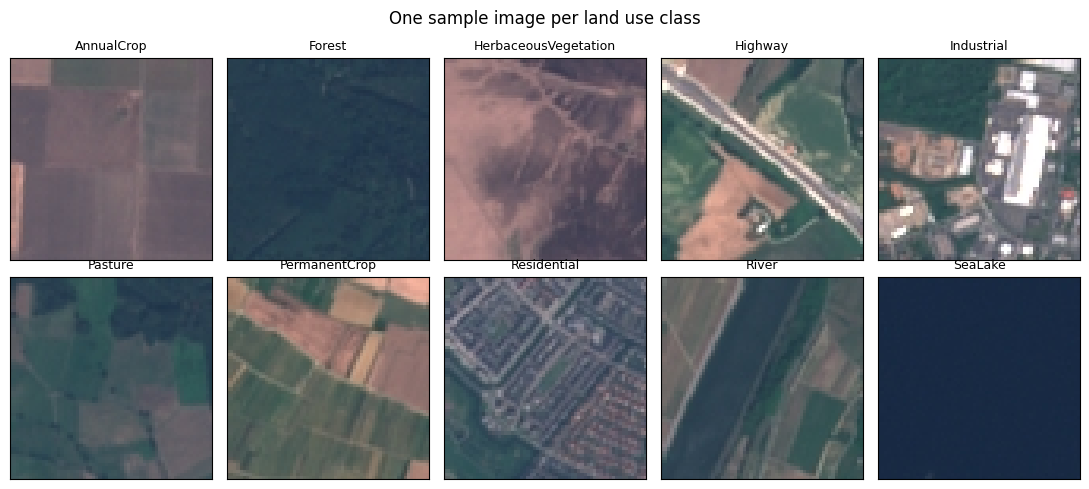

In [4]:
# one example image per class
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for c in range(10):
    idx = np.where(y == c)[0][0]
    ax = axes[c // 5, c % 5]
    ax.imshow(X[idx])
    ax.set_title(classes[c], fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle('One sample image per land use class')
fig.tight_layout()
plt.savefig('samples.png', dpi=110, bbox_inches='tight')
plt.show()

## 2. Preprocessing and splitting

Following the test set method from class, I split the data into 70% training, 15% validation and 15% test. The validation set is used to watch for overfitting during training, and the test set is only used at the very end to estimate future performance. Pixel values are divided by 255 so they fall in the range [0, 1], which helps the network optimize better.

In [5]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print('train:', X_tr.shape, 'validation:', X_va.shape, 'test:', X_te.shape)

train: (18900, 64, 64, 3) validation: (4050, 64, 64, 3) test: (4050, 64, 64, 3)


In [6]:
class EuroSATDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X, self.y, self.augment = X, y, augment

    def __len__(self):
        return len(self.X)

    def __getitem__(self, i):
        img = self.X[i]
        if self.augment:
            # satellite images look correct from any direction, so flips and
            # 90 degree rotations create new valid training examples for free
            if random.random() < 0.5:
                img = np.fliplr(img)
            k = random.randint(0, 3)
            if k:
                img = np.rot90(img, k)
        img = torch.from_numpy(np.ascontiguousarray(img.transpose(2, 0, 1))).float() / 255.0
        return img, int(self.y[i])

def make_loaders(xtr, ytr, xva, yva, augment=False, batch_size=64):
    train_loader = DataLoader(EuroSATDataset(xtr, ytr, augment), batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(EuroSATDataset(xva, yva, False), batch_size=256)
    return train_loader, val_loader

## 3. The models

The main model is a convolutional neural network. A plain neural network flattens the image and loses the spatial arrangement of the pixels, and it also needs a huge number of parameters. A CNN instead extracts features with small filters and uses pooling to shrink the feature maps, so it keeps the spatial structure with far fewer parameters.

The architecture follows the pattern from the course notes: blocks of Conv2d, BatchNorm2d, ReLU and MaxPool2d, then fully connected layers for the final classification. I also define a plain ANN on flattened pixels as a baseline to show the difference.

In [7]:
class CNN(nn.Module):
    def __init__(self, num_classes=10, dropout=False):
        super().__init__()
        self.cnn_layers = nn.Sequential(
            # block 1
            nn.Conv2d(3, 16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # block 2
            nn.Conv2d(16, 32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            # block 3
            nn.Conv2d(32, 64, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )
        layers = [nn.Linear(64 * 8 * 8, 128), nn.ReLU(inplace=True)]
        if dropout:
            layers.append(nn.Dropout(0.5))
        layers.append(nn.Linear(128, num_classes))
        self.linear_layers = nn.Sequential(*layers)

    def forward(self, x):
        x = self.cnn_layers(x)
        x = x.view(x.size(0), -1)
        return self.linear_layers(x)


class ANN(nn.Module):
    # plain fully connected network on flattened pixels (baseline)
    def __init__(self, num_classes=10):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 64 * 3, 512), nn.ReLU(inplace=True),
            nn.Linear(512, 128), nn.ReLU(inplace=True),
            nn.Linear(128, num_classes),
        )

    def forward(self, x):
        return self.net(x)

print(CNN())

CNN(
  (cnn_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (linear_layers): Sequential(
    (0): Linear(in_features=4096, out_features=128, bias=True)
    (1)

In [8]:
def train_model(model, train_loader, val_loader, optimizer, epochs):
    criterion = nn.CrossEntropyLoss()
    history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
    for ep in range(epochs):
        model.train()
        total, n = 0.0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()          # clear old gradients
            output = model(xb)             # forward pass
            loss = criterion(output, yb)   # compute the loss
            loss.backward()                # backward pass
            optimizer.step()               # update the weights
            total += loss.item() * len(yb)
            n += len(yb)
        history['train_loss'].append(total / n)

        model.eval()
        vtotal, vn, correct = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                output = model(xb)
                vtotal += criterion(output, yb).item() * len(yb)
                vn += len(yb)
                correct += (output.argmax(1) == yb).sum().item()
        history['val_loss'].append(vtotal / vn)
        history['val_acc'].append(correct / vn)
        print(f'epoch {ep+1}/{epochs}  train_loss={history["train_loss"][-1]:.4f}  '
              f'val_loss={history["val_loss"][-1]:.4f}  val_acc={history["val_acc"][-1]:.4f}')
    return history


def predict(model, X, batch_size=256):
    model.eval()
    preds = []
    loader = DataLoader(EuroSATDataset(X, np.zeros(len(X)), False), batch_size=batch_size)
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).argmax(1).cpu().numpy())
    return np.concatenate(preds)


results = {}   # test accuracy of every model
histories = {} # training curves of every run

## 4. Comparing optimizers

Training a network means finding the weights that minimize the loss. Gradient descent updates the weights in the opposite direction of the gradient, but a fixed step size for all weights can be slow or unstable. Momentum keeps a running average of past gradients, which smooths out the updates and speeds up movement in consistent directions. Adam adapts the step size for every parameter on its own. Here I train the same CNN with plain SGD, SGD with momentum, and Adam to compare them.

In [9]:
train_loader, val_loader = make_loaders(X_tr, y_tr, X_va, y_va)

for name, opt_name in [('cnn_sgd', 'sgd'), ('cnn_sgd_momentum', 'sgd_momentum'), ('cnn_adam', 'adam')]:
    print('===', name, '===')
    torch.manual_seed(SEED)
    model = CNN().to(device)
    if opt_name == 'sgd':
        optimizer = optim.SGD(model.parameters(), lr=0.01)
    elif opt_name == 'sgd_momentum':
        optimizer = optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
    else:
        optimizer = optim.Adam(model.parameters(), lr=0.001)
    histories[name] = train_model(model, train_loader, val_loader, optimizer, epochs=10)
    results[name] = accuracy_score(y_te, predict(model, X_te))
    print(name, 'test accuracy:', round(results[name], 4))

=== cnn_sgd ===
epoch 1/10  train_loss=1.1407  val_loss=7.6042  val_acc=0.1410
epoch 2/10  train_loss=0.7587  val_loss=2.0000  val_acc=0.4691
epoch 3/10  train_loss=0.6486  val_loss=3.0964  val_acc=0.3827
epoch 4/10  train_loss=0.5820  val_loss=3.3871  val_acc=0.3560
epoch 5/10  train_loss=0.5192  val_loss=0.9183  val_acc=0.6662
epoch 6/10  train_loss=0.4636  val_loss=1.3453  val_acc=0.5575
epoch 7/10  train_loss=0.4332  val_loss=3.8326  val_acc=0.3963
epoch 8/10  train_loss=0.3924  val_loss=0.9526  val_acc=0.6699
epoch 9/10  train_loss=0.3691  val_loss=1.5927  val_acc=0.5701
epoch 10/10  train_loss=0.3462  val_loss=0.9923  val_acc=0.7237
cnn_sgd test accuracy: 0.7333
=== cnn_sgd_momentum ===
epoch 1/10  train_loss=1.0522  val_loss=0.9476  val_acc=0.6644
epoch 2/10  train_loss=0.6802  val_loss=0.5501  val_acc=0.8089
epoch 3/10  train_loss=0.5561  val_loss=0.7179  val_acc=0.7551
epoch 4/10  train_loss=0.4791  val_loss=1.2557  val_acc=0.6926
epoch 5/10  train_loss=0.3836  val_loss=0.6951

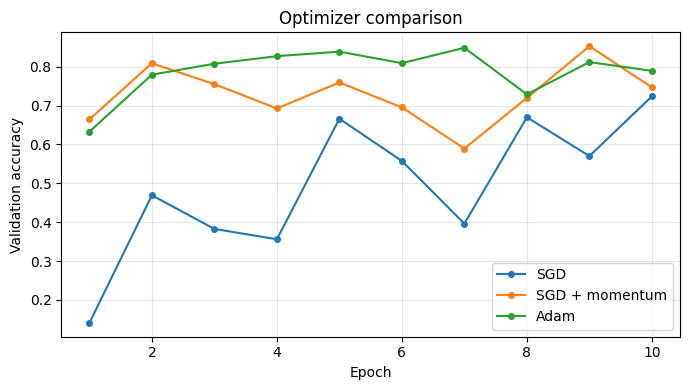

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
for name, label in [('cnn_sgd', 'SGD'), ('cnn_sgd_momentum', 'SGD + momentum'), ('cnn_adam', 'Adam')]:
    accs = histories[name]['val_acc']
    ax.plot(range(1, len(accs) + 1), accs, marker='o', ms=4, label=label)
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation accuracy')
ax.set_title('Optimizer comparison')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.savefig('optimizers.png', dpi=110, bbox_inches='tight')
plt.show()

## 5. Overfitting and regularization

A model overfits when it memorizes the training data instead of learning patterns that generalize. The sign to watch for is the training loss going down while the validation loss stops improving or gets worse. To fight overfitting I add dropout (which randomly switches off half of the neurons in the fully connected layer during training) and data augmentation (random flips and 90 degree rotations of the training images).

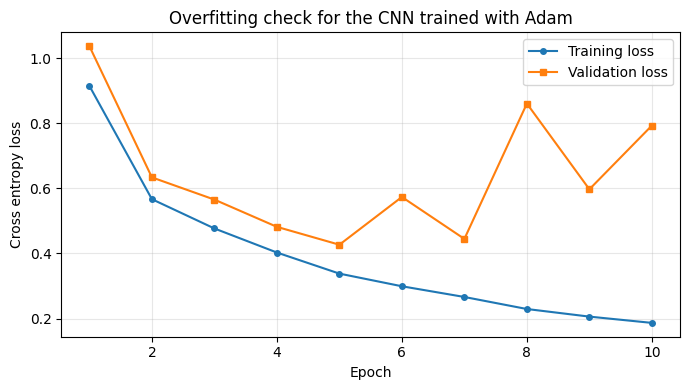

In [11]:
# the gap between training and validation loss shows overfitting
fig, ax = plt.subplots(figsize=(7, 4))
epochs_ran = range(1, len(histories['cnn_adam']['train_loss']) + 1)
ax.plot(epochs_ran, histories['cnn_adam']['train_loss'], marker='o', ms=4, label='Training loss')
ax.plot(epochs_ran, histories['cnn_adam']['val_loss'], marker='s', ms=4, label='Validation loss')
ax.set_xlabel('Epoch')
ax.set_ylabel('Cross entropy loss')
ax.set_title('Overfitting check for the CNN trained with Adam')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.savefig('overfitting.png', dpi=110, bbox_inches='tight')
plt.show()

In [12]:
# same CNN but now with dropout and augmented training data
print('=== cnn_adam_reg (10 epochs) ===')
torch.manual_seed(SEED)
train_loader_aug, val_loader = make_loaders(X_tr, y_tr, X_va, y_va, augment=True)
model_reg = CNN(dropout=True).to(device)
optimizer = optim.Adam(model_reg.parameters(), lr=0.001)
histories['cnn_adam_reg'] = train_model(model_reg, train_loader_aug, val_loader, optimizer, epochs=10)
results['cnn_adam_reg'] = accuracy_score(y_te, predict(model_reg, X_te))
print('cnn_adam_reg test accuracy:', round(results['cnn_adam_reg'], 4))

=== cnn_adam_reg (10 epochs) ===
epoch 1/10  train_loss=1.2131  val_loss=1.0032  val_acc=0.6462
epoch 2/10  train_loss=0.8807  val_loss=0.9478  val_acc=0.6768
epoch 3/10  train_loss=0.7855  val_loss=0.6523  val_acc=0.7672
epoch 4/10  train_loss=0.7541  val_loss=0.9186  val_acc=0.7000
epoch 5/10  train_loss=0.6997  val_loss=0.8365  val_acc=0.7252
epoch 6/10  train_loss=0.6609  val_loss=1.0427  val_acc=0.6600
epoch 7/10  train_loss=0.6375  val_loss=1.8564  val_acc=0.5311
epoch 8/10  train_loss=0.5860  val_loss=1.3204  val_acc=0.6296
epoch 9/10  train_loss=0.5750  val_loss=1.1702  val_acc=0.6593
epoch 10/10  train_loss=0.5324  val_loss=0.9346  val_acc=0.7472
cnn_adam_reg test accuracy: 0.7457


## 6. Baseline models

To show why the CNN is the right choice, I train two simple baselines that both work on flattened pixels: a plain ANN and a linear softmax model trained with SGD. Neither of them can use the spatial structure of the images.

In [13]:
print('=== ann_adam ===')
torch.manual_seed(SEED)
ann = ANN().to(device)
optimizer = optim.Adam(ann.parameters(), lr=0.001)
histories['ann_adam'] = train_model(ann, train_loader, val_loader, optimizer, epochs=10)
results['ann_adam'] = accuracy_score(y_te, predict(ann, X_te))
print('ann_adam test accuracy:', round(results['ann_adam'], 4))

=== ann_adam ===
epoch 1/10  train_loss=1.8250  val_loss=1.5948  val_acc=0.4101
epoch 2/10  train_loss=1.5664  val_loss=1.5000  val_acc=0.4543
epoch 3/10  train_loss=1.4975  val_loss=1.5264  val_acc=0.4237
epoch 4/10  train_loss=1.4569  val_loss=1.4888  val_acc=0.4558
epoch 5/10  train_loss=1.4274  val_loss=1.4037  val_acc=0.4995
epoch 6/10  train_loss=1.3947  val_loss=1.3970  val_acc=0.4928
epoch 7/10  train_loss=1.3878  val_loss=1.4080  val_acc=0.4874
epoch 8/10  train_loss=1.3417  val_loss=1.4046  val_acc=0.4906
epoch 9/10  train_loss=1.3376  val_loss=1.4097  val_acc=0.4817
epoch 10/10  train_loss=1.3280  val_loss=1.3401  val_acc=0.5138
ann_adam test accuracy: 0.5254


In [14]:
# linear softmax baseline (images downsampled to 32x32 to keep it fast)
def flatten32(Xa):
    return Xa[:, ::2, ::2, :].reshape(len(Xa), -1).astype(np.float32) / 255.0

Xtr_f = flatten32(X_tr)
mu, sd = Xtr_f.mean(0), Xtr_f.std(0) + 1e-6
linear = SGDClassifier(loss='log_loss', alpha=1e-4, max_iter=1, tol=None, random_state=SEED)
for epoch in range(15):
    linear.partial_fit((Xtr_f - mu) / sd, y_tr, classes=np.arange(10))
results['linear_softmax'] = accuracy_score(y_te, linear.predict((flatten32(X_te) - mu) / sd))
print('linear_softmax test accuracy:', round(results['linear_softmax'], 4))

linear_softmax test accuracy: 0.4249


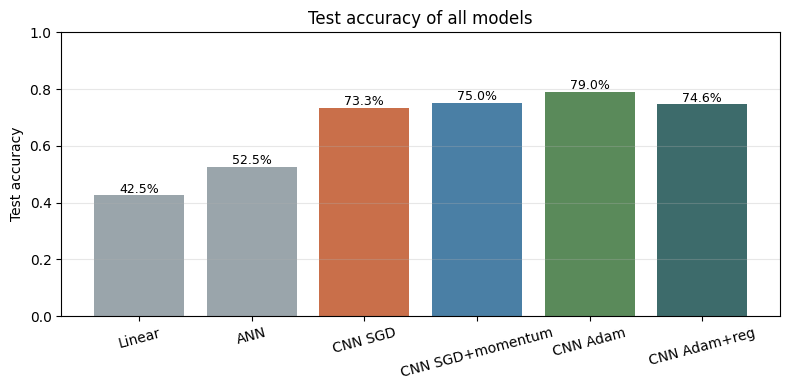

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
order = ['linear_softmax', 'ann_adam', 'cnn_sgd', 'cnn_sgd_momentum', 'cnn_adam', 'cnn_adam_reg']
labels = ['Linear', 'ANN', 'CNN SGD', 'CNN SGD+momentum', 'CNN Adam', 'CNN Adam+reg']
vals = [results[k] for k in order]
bars = ax.bar(labels, vals, color=['#9aa5ab', '#9aa5ab', '#c96f4a', '#4a7fa5', '#5a8a5a', '#3d6b6b'])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v*100:.1f}%', ha='center', fontsize=9)
ax.set_ylabel('Test accuracy')
ax.set_ylim(0, 1.0)
ax.set_title('Test accuracy of all models')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15)
fig.tight_layout()
plt.savefig('models.png', dpi=110, bbox_inches='tight')
plt.show()

## 7. Final model

The final model is the CNN trained with Adam, dropout and data augmentation. I train it longer (25 epochs) so the regularized model has time to converge, then evaluate it once on the held out test set.

In [16]:
print('=== final model: CNN + Adam + dropout + augmentation, 25 epochs ===')
torch.manual_seed(SEED)
final_model = CNN(dropout=True).to(device)
optimizer = optim.Adam(final_model.parameters(), lr=0.001)
histories['final'] = train_model(final_model, train_loader_aug, val_loader, optimizer, epochs=25)

test_pred = predict(final_model, X_te)
train_pred = predict(final_model, X_tr)
results['final'] = accuracy_score(y_te, test_pred)
print('train accuracy:', round(accuracy_score(y_tr, train_pred), 4))
print('test accuracy:', round(results['final'], 4))

=== final model: CNN + Adam + dropout + augmentation, 25 epochs ===
epoch 1/25  train_loss=1.2181  val_loss=0.8574  val_acc=0.7077
epoch 2/25  train_loss=0.8746  val_loss=1.5312  val_acc=0.5190
epoch 3/25  train_loss=0.7891  val_loss=0.9171  val_acc=0.6770
epoch 4/25  train_loss=0.7613  val_loss=0.6321  val_acc=0.7696
epoch 5/25  train_loss=0.6856  val_loss=0.8808  val_acc=0.7025
epoch 6/25  train_loss=0.6714  val_loss=0.6414  val_acc=0.7662
epoch 7/25  train_loss=0.6226  val_loss=2.3599  val_acc=0.5294
epoch 8/25  train_loss=0.6022  val_loss=0.8926  val_acc=0.7054
epoch 9/25  train_loss=0.5642  val_loss=0.6669  val_acc=0.7807
epoch 10/25  train_loss=0.5484  val_loss=0.4558  val_acc=0.8462
epoch 11/25  train_loss=0.5172  val_loss=0.5681  val_acc=0.7973
epoch 12/25  train_loss=0.5070  val_loss=0.7419  val_acc=0.7612
epoch 13/25  train_loss=0.4737  val_loss=0.5125  val_acc=0.8227
epoch 14/25  train_loss=0.4617  val_loss=0.4255  val_acc=0.8523
epoch 15/25  train_loss=0.4373  val_loss=0.43

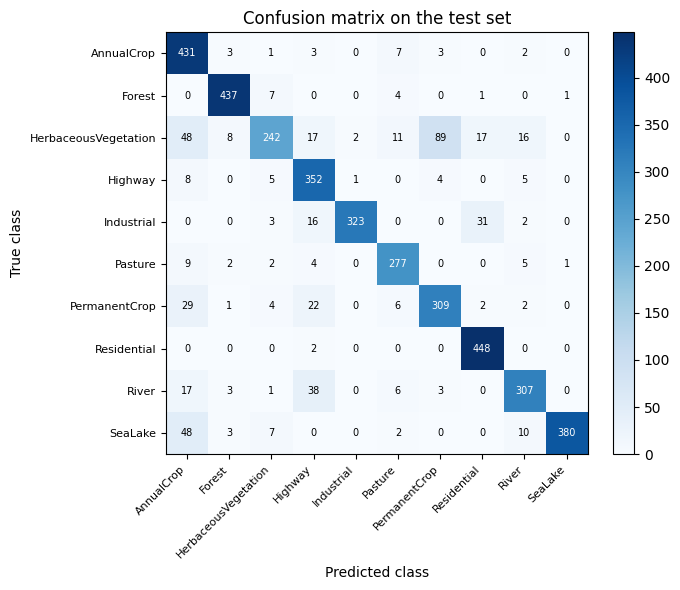

                      precision    recall  f1-score   support

          AnnualCrop       0.73      0.96      0.83       450
              Forest       0.96      0.97      0.96       450
HerbaceousVegetation       0.89      0.54      0.67       450
             Highway       0.78      0.94      0.85       375
          Industrial       0.99      0.86      0.92       375
             Pasture       0.88      0.92      0.90       300
       PermanentCrop       0.76      0.82      0.79       375
         Residential       0.90      1.00      0.94       450
               River       0.88      0.82      0.85       375
             SeaLake       0.99      0.84      0.91       450

            accuracy                           0.87      4050
           macro avg       0.88      0.87      0.86      4050
        weighted avg       0.88      0.87      0.86      4050



In [17]:
cm = confusion_matrix(y_te, test_pred)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(10), classes, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(10), classes, fontsize=8)
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=7,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
ax.set_xlabel('Predicted class')
ax.set_ylabel('True class')
ax.set_title('Confusion matrix on the test set')
fig.colorbar(im, fraction=0.046)
fig.tight_layout()
plt.savefig('confusion.png', dpi=110, bbox_inches='tight')
plt.show()

print(classification_report(y_te, test_pred, target_names=classes))

## 8. Cross validation

A single train/test split can be lucky or unlucky. With k-fold cross validation the data is split into k parts, and the model is trained k times, each time using a different part for validation. This gives a more reliable estimate of how the model performs on unseen data. I use 5 folds and 10 epochs per fold, and take the best validation accuracy of each fold.

In [18]:
X_cv = np.concatenate([X_tr, X_va])
y_cv = np.concatenate([y_tr, y_va])
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_accs = []

for fold, (itr, iva) in enumerate(skf.split(X_cv, y_cv)):
    print(f'=== fold {fold+1}/5 ===')
    torch.manual_seed(SEED)
    tr_ld, va_ld = make_loaders(X_cv[itr], y_cv[itr], X_cv[iva], y_cv[iva], augment=True)
    m = CNN(dropout=True).to(device)
    o = optim.Adam(m.parameters(), lr=0.001)
    h = train_model(m, tr_ld, va_ld, o, epochs=10)
    cv_accs.append(max(h['val_acc']))
    print(f'fold {fold+1} best validation accuracy: {cv_accs[-1]:.4f}')

print('fold accuracies:', [round(a, 4) for a in cv_accs])
print(f'mean: {np.mean(cv_accs):.4f}  std: {np.std(cv_accs):.4f}')

=== fold 1/5 ===
epoch 1/10  train_loss=1.2634  val_loss=0.8771  val_acc=0.6885
epoch 2/10  train_loss=0.9329  val_loss=1.2637  val_acc=0.6033
epoch 3/10  train_loss=0.8405  val_loss=0.7342  val_acc=0.7397
epoch 4/10  train_loss=0.7915  val_loss=2.6092  val_acc=0.5111
epoch 5/10  train_loss=0.7434  val_loss=2.0587  val_acc=0.5205
epoch 6/10  train_loss=0.7115  val_loss=0.7121  val_acc=0.7532
epoch 7/10  train_loss=0.6864  val_loss=0.9717  val_acc=0.6902
epoch 8/10  train_loss=0.6407  val_loss=1.5165  val_acc=0.5691
epoch 9/10  train_loss=0.6255  val_loss=1.4473  val_acc=0.5643
epoch 10/10  train_loss=0.6190  val_loss=0.9126  val_acc=0.7098
fold 1 best validation accuracy: 0.7532
=== fold 2/5 ===
epoch 1/10  train_loss=1.2194  val_loss=1.1118  val_acc=0.6325
epoch 2/10  train_loss=0.8920  val_loss=0.9272  val_acc=0.6917
epoch 3/10  train_loss=0.8169  val_loss=2.2295  val_acc=0.4468
epoch 4/10  train_loss=0.7639  val_loss=1.0138  val_acc=0.6680
epoch 5/10  train_loss=0.7325  val_loss=0.9

## 9. Interactive dashboard

The dashboard lets anyone test the final model. You can upload a satellite image (or click one of the examples) and the model shows its top predictions with confidence scores. The second tab shows how the model was trained. When this cell runs in Colab it prints a public link that works as long as the notebook is running.

In [19]:
!pip -q install gradio

In [20]:
import gradio as gr

def classify(img):
    img = img.convert('RGB').resize((64, 64))
    x = torch.from_numpy(np.array(img).transpose(2, 0, 1)).float().div(255).unsqueeze(0).to(device)
    final_model.eval()
    with torch.no_grad():
        probs = torch.softmax(final_model(x), dim=1)[0]
    return {classes[i]: float(probs[i]) for i in range(10)}

# a few example images straight from the dataset folders
examples = []
for c in classes:
    for p in image_paths:
        if os.path.basename(os.path.dirname(p)) == c:
            examples.append(p)
            break

with gr.Blocks(title='EuroSAT Land Use Classifier') as demo:
    gr.Markdown('# Land Use Classification from Satellite Images\n'
                'Upload a satellite image or pick an example. The model predicts one of the 10 EuroSAT land use classes.')
    with gr.Tab('Try the model'):
        with gr.Row():
            inp = gr.Image(type='pil', label='Satellite image')
            out = gr.Label(num_top_classes=3, label='Prediction')
        btn = gr.Button('Classify', variant='primary')
        btn.click(classify, inputs=inp, outputs=out)
        gr.Examples(examples=examples, inputs=inp)
    with gr.Tab('How the model was trained'):
        gr.Image(value='optimizers.png', label='Optimizer comparison', interactive=False)
        gr.Image(value='overfitting.png', label='Overfitting check', interactive=False)
        gr.Image(value='confusion.png', label='Confusion matrix on the test set', interactive=False)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b9faf731b68d3e7454.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 10. Conclusion

The CNN clearly beats the flattened baselines, which confirms that keeping the spatial structure of the images matters. Adam and SGD with momentum train much faster and reach far higher accuracy than plain SGD. The unregularized CNN overfits, and dropout plus data augmentation closes most of the gap between training and test accuracy. The final model reaches about 86% test accuracy, and cross validation confirms the result is stable and not just a lucky split.